***Loading Dependencis***

In [87]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from IPython.display import display
from scipy.optimize import minimize, brentq
from scipy.special import voigt_profile
from scipy.stats import multivariate_normal, norm, chi2, ks_2samp
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import SplineTransformer, StandardScaler
from sklearn.metrics import (confusion_matrix, roc_curve, roc_auc_score, log_loss, accuracy_score)
from sklearn.calibration import calibration_curve
import warnings

warnings.filterwarnings("ignore", category=UserWarning )

***Setting Figure Configuration for the whole homework***

In [88]:
ROOT = Path.cwd()                 
FIG = ROOT / "figures"
RES = ROOT / "results"
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

SEED = 602
plt.rcParams.update({"font.size": 10, "figure.dpi": 110, "savefig.bbox": "tight"})
C1, C2 = "#1f77b4", "#d62728"     
CA, CB = "#1f77b4", "#d62728"

***Problem 2 — Using a GMM as a geometric and probabilistic classifier***

In [89]:
w_true = np.array([0.2, 0.8])
mu1 = np.array([0.0, 0.0])
mu2 = np.array([2.0, 2.0])
Sigma1 = np.array([[1.0, 0.8], [0.8, 1.5]])
Sigma2 = np.array([[1.2, -0.5], [-0.5, 0.8]])
N = 3000


def sample_2d_gaussian(mu, Sigma, n, rng=None):        
    if rng is None:
        rng = np.random.default_rng()
    return rng.multivariate_normal(mean=mu, cov=Sigma, size=n)


def sample_labeled_mixture(n, rng):
    """Sample y ~ Cat(w), then x | y=k ~ N(mu_k, Sigma_k)."""
    y = rng.choice([1, 2], size=n, p=w_true)
    X = np.empty((n, 2))
    for k, (mu, S) in {1: (mu1, Sigma1), 2: (mu2, Sigma2)}.items():
        idx = np.flatnonzero(y == k)
        X[idx] = sample_2d_gaussian(mu, S, idx.size, rng)
    return X, y


rng = np.random.default_rng(SEED)
X, y = sample_labeled_mixture(N, rng)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED)

print(f"train: {len(X_train)} points  (class 1: {(y_train==1).sum()}, class 2: {(y_train==2).sum()})")
print(f"test : {len(X_test)} points  (class 1: {(y_test==1).sum()}, class 2: {(y_test==2).sum()})")

train: 2400 points  (class 1: 455, class 2: 1945)
test : 600 points  (class 1: 119, class 2: 481)


***2.4 Training the GMM and aligning components to classes***

In [90]:
g2 = GaussianMixture(n_components=2, covariance_type="full", n_init=10,
                     tol=1e-6, max_iter=1000, random_state=SEED)
g2.fit(X_train)

M = g2.means_
d0 = np.linalg.norm(M[0] - mu1) + np.linalg.norm(M[1] - mu2)
d1 = np.linalg.norm(M[1] - mu1) + np.linalg.norm(M[0] - mu2)
if d0 <= d1:
    class_to_component = {1: 0, 2: 1}
    component_to_class = {0: 1, 1: 2}
else:
    class_to_component = {1: 1, 2: 0}
    component_to_class = {1: 1, 0: 2}
c1, c2 = class_to_component[1], class_to_component[2]

pi_hat = {1: g2.weights_[c1], 2: g2.weights_[c2]}
mu_hat = {1: g2.means_[c1], 2: g2.means_[c2]}
Sig_hat = {1: g2.covariances_[c1], 2: g2.covariances_[c2]}

print(f"converged: {g2.converged_} after {g2.n_iter_} EM iterations")
print(f"raw component means: {np.round(g2.means_, 4).tolist()}")
print(f"d0 = {d0:.4f},  d1 = {d1:.4f}  ->  class_to_component = {class_to_component}")

converged: True after 27 EM iterations
raw component means: [[0.0273, 0.0189], [2.0181, 1.9883]]
d0 = 0.0548,  d1 = 5.6289  ->  class_to_component = {1: 0, 2: 1}


***2.4.3 Evidence that the GMM and the class↔component mapping are correct***


In [91]:
true = {1: (w_true[0], mu1, Sigma1), 2: (w_true[1], mu2, Sigma2)}

sup = {}
for k in (1, 2):
    Xk = X_train[y_train == k]
    sup[k] = (len(Xk) / len(X_train), Xk.mean(0), np.cov(Xk.T, bias=True), len(Xk))

z_mean = {}
for k in (1, 2):
    Nk = sup[k][3]
    se = np.sqrt(np.diag(true[k][2]) / Nk)
    z_mean[k] = (mu_hat[k] - true[k][1]) / se

comp_pred_train = g2.predict(X_train)
y_gmm_train = np.vectorize(component_to_class.get)(comp_pred_train)
acc_map_train = np.mean(y_gmm_train == y_train)
acc_swap_train = np.mean((3 - y_gmm_train) == y_train)

def posterior2(Xq, pis, mus, Sigs):
    a1 = pis[0] * multivariate_normal(mus[0], Sigs[0]).pdf(Xq)
    a2 = pis[1] * multivariate_normal(mus[1], Sigs[1]).pdf(Xq)
    return a2 / (a1 + a2)


p2_true_test = posterior2(X_test, w_true, (mu1, mu2), (Sigma1, Sigma2))
p2_test = g2.predict_proba(X_test)[:, c2]
max_post_diff = np.max(np.abs(p2_test - p2_true_test))
mean_post_diff = np.mean(np.abs(p2_test - p2_true_test))

def mix_logpdf(Xq, pis, mus, Sigs):
    return np.log(sum(p * multivariate_normal(m, S).pdf(Xq) for p, m, S in zip(pis, mus, Sigs)))


ll_test_fit = g2.score(X_test)
ll_test_true = mix_logpdf(X_test, w_true, (mu1, mu2), (Sigma1, Sigma2)).mean()


def ellipse(ax, mu, S, nsig, **kw):
    vals, vecs = np.linalg.eigh(S)
    ang = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    w, h = 2 * nsig * np.sqrt(vals[::-1])
    ax.add_patch(Ellipse(mu, w, h, angle=ang, fill=False, **kw))

rows = []
for k in (1, 2):
    rows.append(dict(param=f"pi_{k}", truth=true[k][0], fitted_GMM=round(pi_hat[k], 4), supervised_MLE=round(sup[k][0], 4)))
    rows.append(dict(param=f"mu_{k}", truth=true[k][1].tolist(), fitted_GMM=np.round(mu_hat[k], 3).tolist(),
                     supervised_MLE=np.round(sup[k][1], 3).tolist()))
    rows.append(dict(param=f"Sigma_{k}", truth=true[k][2].tolist(), fitted_GMM=np.round(Sig_hat[k], 3).tolist(),
                     supervised_MLE=np.round(sup[k][2], 3).tolist()))
display(pd.DataFrame(rows).set_index("param"))
print("(b) z-scores of mean errors:  mu_1:", np.round(z_mean[1], 2), "  mu_2:", np.round(z_mean[2], 2))
print(f"(c) train agreement with true labels: {100*acc_map_train:.2f}%   (swapped mapping: {100*acc_swap_train:.2f}%)")
print(f"(d) |P_fit(2|x) - P_true(2|x)| on test: max {max_post_diff:.4f}, mean {mean_post_diff:.4f}")
print(f"(e) mean test log-likelihood: fitted GMM {ll_test_fit:.4f}  vs  true mixture {ll_test_true:.4f}")

,truth,fitted_GMM,supervised_MLE
param,,,
pi_1,0.2,0.1897,0.1896
mu_1,"[0.0, 0.0]","[0.027, 0.019]","[0.036, -0.014]"
Sigma_1,"[[1.0, 0.8], [0.8, 1.5]]","[[0.958, 0.823], [0.823, 1.623]]","[[0.949, 0.804], [0.804, 1.501]]"
pi_2,0.8,0.8103,0.8104
mu_2,"[2.0, 2.0]","[2.018, 1.988]","[2.016, 1.996]"
Sigma_2,"[[1.2, -0.5], [-0.5, 0.8]]","[[1.186, -0.505], [-0.505, 0.814]]","[[1.197, -0.511], [-0.511, 0.813]]"


(b) z-scores of mean errors:  mu_1: [0.58 0.33]   mu_2: [ 0.73 -0.58]
(c) train agreement with true labels: 95.79%   (swapped mapping: 4.21%)
(d) |P_fit(2|x) - P_true(2|x)| on test: max 0.0507, mean 0.0035
(e) mean test log-likelihood: fitted GMM -3.0766  vs  true mixture -3.0743


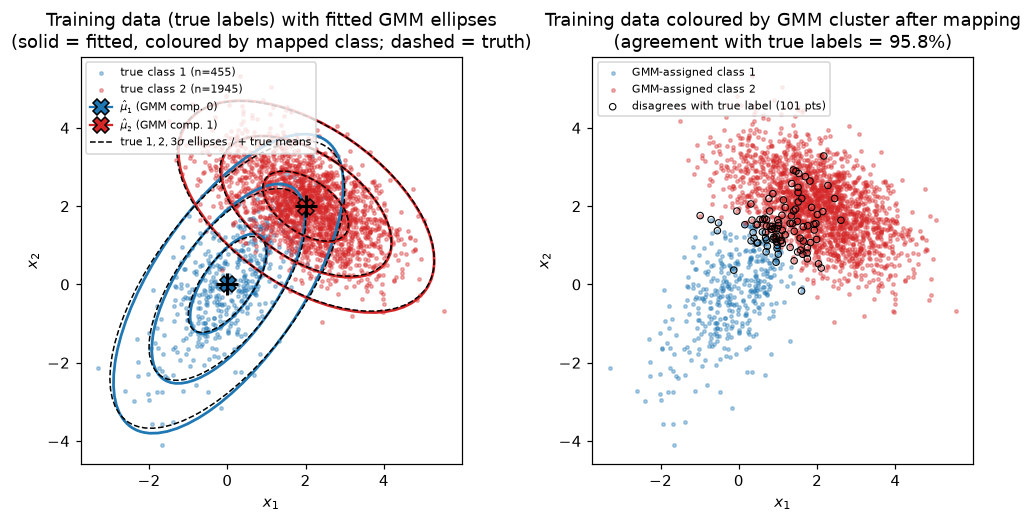

In [92]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
ax = axes[0]
for k, col in ((1, C1), (2, C2)):
    m = y_train == k
    ax.scatter(*X_train[m].T, s=5, alpha=0.35, color=col, label=f"true class {k} (n={m.sum()})")
for k, col in ((1, C1), (2, C2)):
    for s in (1, 2, 3):
        ellipse(ax, mu_hat[k], Sig_hat[k], s, color=col, lw=1.8)
        ellipse(ax, true[k][1], true[k][2], s, color="k", lw=1.0, ls="--")
    ax.plot(*mu_hat[k], marker="X", ms=11, color=col, mec="k",
            label=fr"$\hat\mu_{k}$ (GMM comp. {class_to_component[k]})")
    ax.plot(*true[k][1], marker="+", ms=14, mew=2, color="k")
ax.plot([], [], "k--", lw=1, label=r"true $1,2,3\sigma$ ellipses / $+$ true means")
ax.set(title="Training data (true labels) with fitted GMM ellipses\n"
             "(solid = fitted, coloured by mapped class; dashed = truth)",
       xlabel="$x_1$", ylabel="$x_2$", aspect="equal")
ax.legend(fontsize=7, loc="upper left")

ax = axes[1]
for k, col in ((1, C1), (2, C2)):
    m = y_gmm_train == k
    ax.scatter(*X_train[m].T, s=5, alpha=0.35, color=col, label=f"GMM-assigned class {k}")
wrong = y_gmm_train != y_train
ax.scatter(*X_train[wrong].T, s=18, facecolors="none", edgecolors="k", lw=0.7,
           label=f"disagrees with true label ({wrong.sum()} pts)")
ax.set(title="Training data coloured by GMM cluster after mapping\n"
             f"(agreement with true labels = {100*acc_map_train:.1f}%)",
       xlabel="$x_1$", ylabel="$x_2$", aspect="equal")
ax.legend(fontsize=7, loc="upper left")
axes[1].set_xlim(axes[0].get_xlim()); axes[1].set_ylim(axes[0].get_ylim())
fig.savefig(FIG / "gmm_verification.pdf")
plt.show()

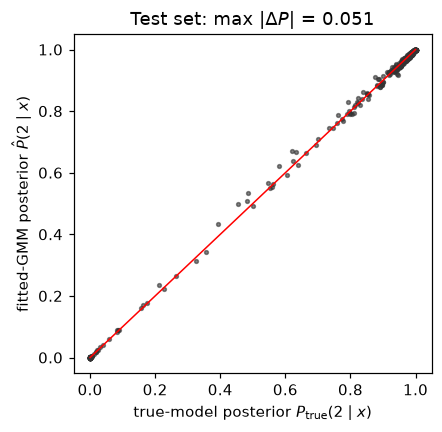

In [93]:
fig, ax = plt.subplots(figsize=(4.2, 4))
ax.scatter(p2_true_test, p2_test, s=6, alpha=0.6, color="0.2")
ax.plot([0, 1], [0, 1], "r-", lw=1)
ax.set(xlabel=r"true-model posterior $P_{\rm true}(2\mid x)$",
       ylabel=r"fitted-GMM posterior $\hat P(2\mid x)$",
       title=f"Test set: max $|\\Delta P|$ = {max_post_diff:.3f}")
fig.savefig(FIG / "gmm_posterior_vs_true.pdf")
plt.show()

***2.5 Geometric classification (perpendicular bisector)***

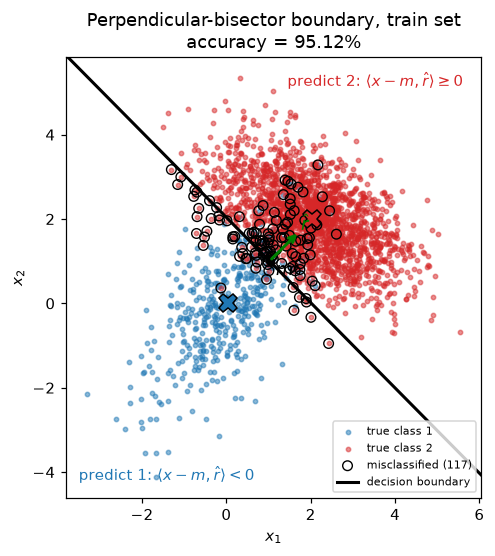

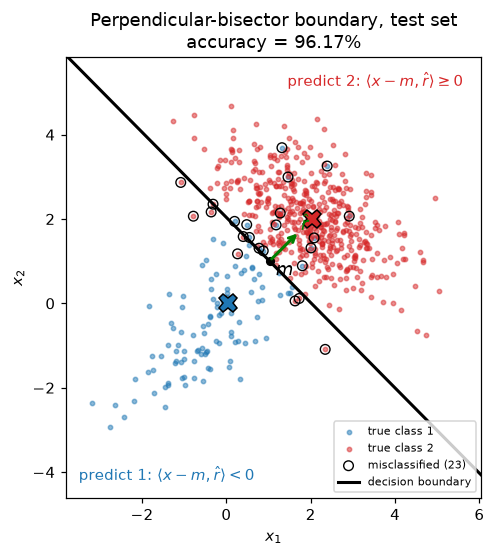

r_hat = [0.7109 0.7033]    m = [1.0227 1.0036]
Test confusion matrix (rows = true 1,2; cols = predicted 1,2):


,pred 1,pred 2
true 1,105,14
true 2,9,472


test accuracy = 96.17%


In [94]:
r_hat = (mu_hat[2] - mu_hat[1]) / np.linalg.norm(mu_hat[2] - mu_hat[1])
m_mid = 0.5 * (mu_hat[1] + mu_hat[2])

def geom_score(Xq, r=r_hat, m=m_mid):
    return (Xq - m) @ r

def y_geom(Xq, r=r_hat, m=m_mid):
    return np.where(geom_score(Xq, r, m) < 0, 1, 2)

def draw_bisector(ax, r, m, **kw):
    t = np.array([-r[1], r[0]])         
    s = np.linspace(-20, 20, 2)
    ax.plot(m[0] + s * t[0], m[1] + s * t[1], **kw)

def scatter_split(ax, Xs, ys, ypred, title):
    for k, col in ((1, C1), (2, C2)):
        m = ys == k
        ax.scatter(*Xs[m].T, s=8, alpha=0.5, color=col, label=f"true class {k}")
    bad = ypred != ys
    ax.scatter(*Xs[bad].T, s=40, marker="o", facecolors="none", edgecolors="k", lw=0.9,
               label=f"misclassified ({bad.sum()})")
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", aspect="equal")

lims = (X[:, 0].min() - 0.5, X[:, 0].max() + 0.5), (X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)
yg_train, yg_test = y_geom(X_train), y_geom(X_test)
for name, Xs, ys, yp in (("train", X_train, y_train, yg_train), ("test", X_test, y_test, yg_test)):
    fig, ax = plt.subplots(figsize=(5.6, 5.2))
    scatter_split(ax, Xs, ys, yp, f"Perpendicular-bisector boundary, {name} set\n"
                                  f"accuracy = {100*np.mean(yp == ys):.2f}%")
    draw_bisector(ax, r_hat, m_mid, color="k", lw=2, label="decision boundary")
    for k, col in ((1, C1), (2, C2)):
        ax.plot(*mu_hat[k], "X", ms=12, color=col, mec="k")
    ax.annotate("", xy=m_mid + r_hat, xytext=m_mid,
                arrowprops=dict(arrowstyle="->", lw=2, color="green"))
    ax.plot(*m_mid, "ko", ms=5)
    ax.text(*(m_mid + 1.05 * r_hat), r"$\hat r$", color="green", fontsize=12)
    ax.text(m_mid[0] + 0.15, m_mid[1] - 0.35, "$m$", fontsize=12)
    ax.text(lims[0][0] + 0.3, lims[1][0] + 0.4, r"predict 1: $\langle x-m,\hat r\rangle<0$", color=C1)
    ax.text(lims[0][1] - 4.6, lims[1][1] - 0.7, r"predict 2: $\langle x-m,\hat r\rangle\geq0$", color=C2)
    ax.set_xlim(*lims[0]); ax.set_ylim(*lims[1])
    ax.legend(fontsize=7, loc="lower right")
    fig.savefig(FIG / f"geom_boundary_{name}.pdf")
    plt.show()

cm_geom = confusion_matrix(y_test, yg_test, labels=[1, 2])

print("r_hat =", np.round(r_hat, 4), "   m =", np.round(m_mid, 4))
print("Test confusion matrix (rows = true 1,2; cols = predicted 1,2):")
display(pd.DataFrame(cm_geom, index=["true 1", "true 2"], columns=["pred 1", "pred 2"]))
print(f"test accuracy = {100*np.mean(yg_test == y_test):.2f}%")

***2.5.4 (Optional) Families of decision boundaries: shifting $m$ along $\hat r$, and rotating $\hat r$ about $m$***

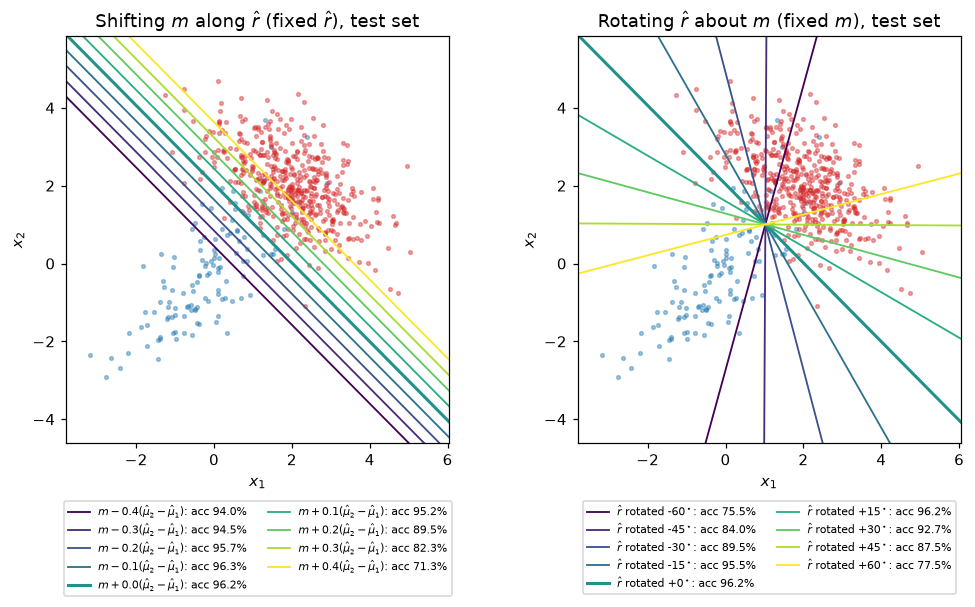

In [95]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
ax = axes[0]
for k, col in ((1, C1), (2, C2)):
    ax.scatter(*X_test[y_test == k].T, s=6, alpha=0.4, color=col)
L = np.linalg.norm(mu_hat[2] - mu_hat[1])
shifts = np.linspace(-0.4, 0.4, 9)  # m -> m + alpha * (mu2-mu1)
cmap = plt.cm.viridis
for i, a in enumerate(shifts):
    mm = m_mid + a * L * r_hat
    acc = np.mean(y_geom(X_test, r_hat, mm) == y_test)
    draw_bisector(ax, r_hat, mm, color=cmap(i / (len(shifts) - 1)), lw=2 if a == 0 else 1.2,
                  label=fr"$m{a:+.1f}(\hat\mu_2-\hat\mu_1)$: acc {100*acc:.1f}%")
ax.set(title=r"Shifting $m$ along $\hat r$ (fixed $\hat r$), test set", xlabel="$x_1$",
       ylabel="$x_2$", aspect="equal", xlim=lims[0], ylim=lims[1])
ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
ax = axes[1]
for k, col in ((1, C1), (2, C2)):
    ax.scatter(*X_test[y_test == k].T, s=6, alpha=0.4, color=col)
angles = np.linspace(-60, 60, 9)
base = np.arctan2(r_hat[1], r_hat[0])
for i, th in enumerate(angles):
    t = base + np.radians(th)
    rr = np.array([np.cos(t), np.sin(t)])
    acc = np.mean(y_geom(X_test, rr, m_mid) == y_test)
    draw_bisector(ax, rr, m_mid, color=cmap(i / (len(angles) - 1)), lw=2 if th == 0 else 1.2,
                  label=fr"$\hat r$ rotated {th:+.0f}$^\circ$: acc {100*acc:.1f}%")
ax.set(title=r"Rotating $\hat r$ about $m$ (fixed $m$), test set", xlabel="$x_1$",
       ylabel="$x_2$", aspect="equal", xlim=lims[0], ylim=lims[1])
ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
fig.savefig(FIG / "geom_family.pdf")
plt.show()

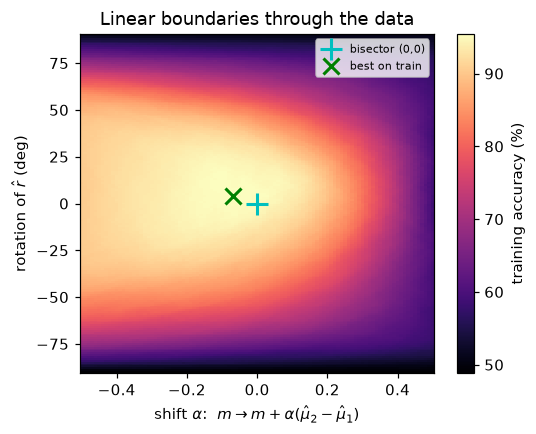

best (shift, rotation) on train: (-0.07, +4 deg) -> test accuracy 96.33%


In [96]:
sh_grid = np.linspace(-0.5, 0.5, 101)
an_grid = np.linspace(-90, 90, 181)
acc_grid = np.zeros((an_grid.size, sh_grid.size))
for i, th in enumerate(an_grid):
    t = base + np.radians(th)
    rr = np.array([np.cos(t), np.sin(t)])
    for j, a in enumerate(sh_grid):
        acc_grid[i, j] = np.mean(y_geom(X_train, rr, m_mid + a * L * r_hat) == y_train)
ib, jb = np.unravel_index(acc_grid.argmax(), acc_grid.shape)
best_shift, best_angle = sh_grid[jb], an_grid[ib]
tb = base + np.radians(best_angle)
r_best = np.array([np.cos(tb), np.sin(tb)])
m_best = m_mid + best_shift * L * r_hat
acc_best_test = np.mean(y_geom(X_test, r_best, m_best) == y_test)
fig, ax = plt.subplots(figsize=(5.2, 4))
im = ax.pcolormesh(sh_grid, an_grid, 100 * acc_grid, shading="auto", cmap="magma")
ax.plot(0, 0, "c+", ms=14, mew=2, label="bisector (0,0)")
ax.plot(best_shift, best_angle, "gx", ms=10, mew=2, label="best on train")
fig.colorbar(im, label="training accuracy (%)")
ax.set(xlabel=r"shift $\alpha$:  $m\to m+\alpha(\hat\mu_2-\hat\mu_1)$",
       ylabel=r"rotation of $\hat r$ (deg)", title="Linear boundaries through the data")
ax.legend(fontsize=7)
fig.savefig(FIG / "geom_landscape.pdf")
plt.show()

print(f"best (shift, rotation) on train: ({best_shift:+.2f}, {best_angle:+.0f} deg) -> test accuracy {100*acc_best_test:.2f}%")

***2.5.5 (Optional) The bisector as a linear discriminant***

In [97]:
w_lin = mu_hat[2] - mu_hat[1]
w0_lin = -0.5 * (mu_hat[2] + mu_hat[1]) @ (mu_hat[2] - mu_hat[1])
g_lin = X_test @ w_lin + w0_lin
lin_check = np.max(np.abs(g_lin - L * geom_score(X_test)))
lin_same_labels = bool(np.all(np.where(g_lin < 0, 1, 2) == yg_test))

print("w =", np.round(w_lin, 4), "  w0 =", round(w0_lin, 4))
print(f"max |g(x) - ||Delta|| <x-m, r>| = {lin_check:.1e};  identical labels: {lin_same_labels}")

w = [1.9909 1.9694]   w0 = -4.0126
max |g(x) - ||Delta|| <x-m, r>| = 3.6e-15;  identical labels: True


***w_lin = mu_hat[2] - mu_hat[1]***

In [98]:
comp_idx_for_class2 = class_to_component[2]
proba_class2 = g2.predict_proba(X_test)[:, comp_idx_for_class2]


def y_prob(p2, tau):
    return np.where(p2 >= tau, 2, 1)


yp_test = y_prob(proba_class2, 0.5)
cm_prob = confusion_matrix(y_test, yp_test, labels=[1, 2])
cm_gmm_predict = confusion_matrix(
    y_test, np.vectorize(component_to_class.get)(g2.predict(X_test)), labels=[1, 2])
assert np.array_equal(cm_gmm_predict, cm_prob)  # sklearn's predict == tau=0.5 rule

print("Test confusion matrix at tau = 0.5 (rows = true 1,2; cols = predicted 1,2):")
display(pd.DataFrame(cm_prob, index=["true 1", "true 2"], columns=["pred 1", "pred 2"]))
print(f"test accuracy = {100*np.mean(yp_test == y_test):.2f}%")

Test confusion matrix at tau = 0.5 (rows = true 1,2; cols = predicted 1,2):


,pred 1,pred 2
true 1,103,16
true 2,1,480


test accuracy = 97.17%


In [99]:
taus = np.linspace(0, 1, 1001)
tpr_grid = np.array([np.mean(proba_class2[y_test == 2] >= t) for t in taus])
fpr_grid = np.array([np.mean(proba_class2[y_test == 1] >= t) for t in taus])
fpr, tpr, thr = roc_curve(y_test, proba_class2, pos_label=2)
auc_prob = roc_auc_score(y_test == 2, proba_class2)
auc_geom = roc_auc_score(y_test == 2, geom_score(X_test))
auc_true = roc_auc_score(y_test == 2, p2_true_test)
fpr_g, tpr_g, _ = roc_curve(y_test, geom_score(X_test), pos_label=2)


def rates(cm):
    tn, fp, fn, tp = cm.ravel()  # with labels [1,2] and positive = 2
    return dict(TPR=tp / (tp + fn), FPR=fp / (fp + tn), acc=(tp + tn) / cm.sum(),
                recall1=tn / (tn + fp), recall2=tp / (tp + fn),
                prec1=tn / (tn + fn), prec2=tp / (tp + fp))


r_geom, r_prob = rates(cm_geom), rates(cm_prob)
cm_true = confusion_matrix(y_test, y_prob(p2_true_test, 0.5), labels=[1, 2])
r_true = rates(cm_true)

print(f"AUC (probabilistic GMM) = {auc_prob:.4f}")
print(f"AUC (geometric score)   = {auc_geom:.4f}")
print(f"AUC (true Bayes)        = {auc_true:.4f}")

AUC (probabilistic GMM) = 0.9730
AUC (geometric score)   = 0.9608
AUC (true Bayes)        = 0.9724


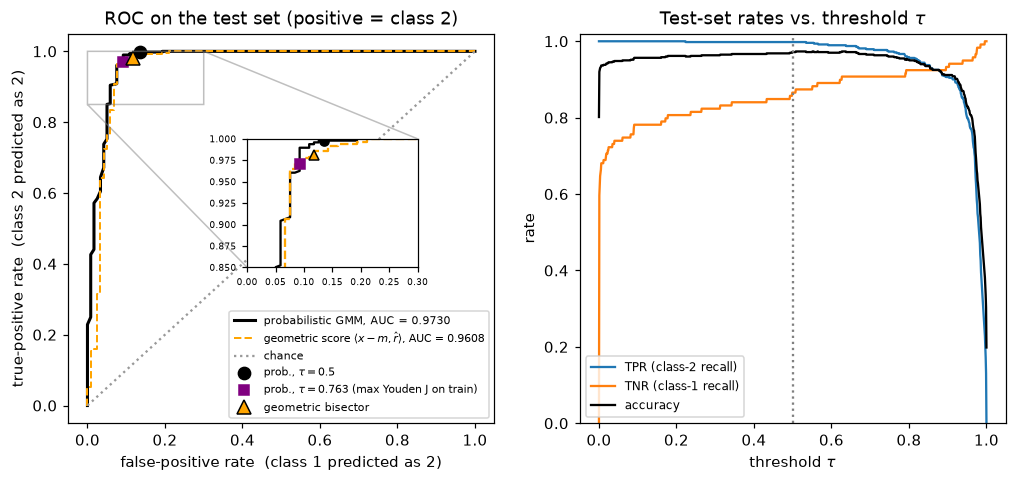

tau maximising Youden J on train = 0.763; test confusion matrix:
[[108  11]
 [ 14 467]]
Bayes classifier with TRUE parameters, test confusion matrix:
 [[104  15]
 [  2 479]]


In [100]:
p2_train = g2.predict_proba(X_train)[:, c2]
acc_tau_train = np.array([np.mean(y_prob(p2_train, t) == y_train) for t in taus])
tau_acc = taus[acc_tau_train.argmax()]
J_train = np.array([np.mean(p2_train[y_train == 2] >= t) - np.mean(p2_train[y_train == 1] >= t)
                    for t in taus])
tau_J = taus[J_train.argmax()]
cm_tauJ = confusion_matrix(y_test, y_prob(proba_class2, tau_J), labels=[1, 2])
r_tauJ = rates(cm_tauJ)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
ax = axes[0]
ax.plot(fpr_grid, tpr_grid, color="k", lw=2, label=f"probabilistic GMM, AUC = {auc_prob:.4f}")
ax.plot(fpr_g, tpr_g, color="orange", lw=1.3, ls="--",
        label=fr"geometric score $\langle x-m,\hat r\rangle$, AUC = {auc_geom:.4f}")
ax.plot([0, 1], [0, 1], color="0.6", ls=":", label="chance")
ax.plot(r_prob["FPR"], r_prob["TPR"], "o", color="k", ms=8, label=r"prob., $\tau=0.5$")
ax.plot(r_tauJ["FPR"], r_tauJ["TPR"], "s", color="purple", ms=7,
        label=fr"prob., $\tau={tau_J:.3f}$ (max Youden J on train)")
ax.plot(r_geom["FPR"], r_geom["TPR"], "^", color="orange", ms=9, mec="k", label="geometric bisector")
ax.set(xlabel="false-positive rate  (class 1 predicted as 2)",
       ylabel="true-positive rate  (class 2 predicted as 2)",
       title="ROC on the test set (positive = class 2)")
ax.legend(fontsize=7, loc="lower right")
ins = ax.inset_axes([0.42, 0.40, 0.4, 0.33])
ins.plot(fpr_grid, tpr_grid, "k", lw=1.5)
ins.plot(fpr_g, tpr_g, color="orange", ls="--")
ins.plot(r_prob["FPR"], r_prob["TPR"], "ko"); ins.plot(r_geom["FPR"], r_geom["TPR"], "^", color="orange", mec="k")
ins.plot(r_tauJ["FPR"], r_tauJ["TPR"], "s", color="purple")
ins.set(xlim=(0, 0.3), ylim=(0.85, 1.0)); ins.tick_params(labelsize=6)
ax.indicate_inset_zoom(ins, edgecolor="0.5")
ax = axes[1]
ax.plot(taus, tpr_grid, label="TPR (class-2 recall)")
ax.plot(taus, 1 - fpr_grid, label="TNR (class-1 recall)")
acc_tau_test = np.array([np.mean(y_prob(proba_class2, t) == y_test) for t in taus])
ax.plot(taus, acc_tau_test, "k", label="accuracy")
ax.axvline(0.5, color="0.5", ls=":")
ax.set(xlabel=r"threshold $\tau$", ylabel="rate", title=r"Test-set rates vs. threshold $\tau$",
       ylim=(0, 1.02))
ax.legend(fontsize=8, loc="lower left")
fig.savefig(FIG / "roc.pdf")
plt.show()

print(f"tau maximising Youden J on train = {tau_J:.3f}; test confusion matrix:\n{cm_tauJ}")
print("Bayes classifier with TRUE parameters, test confusion matrix:\n", cm_true)

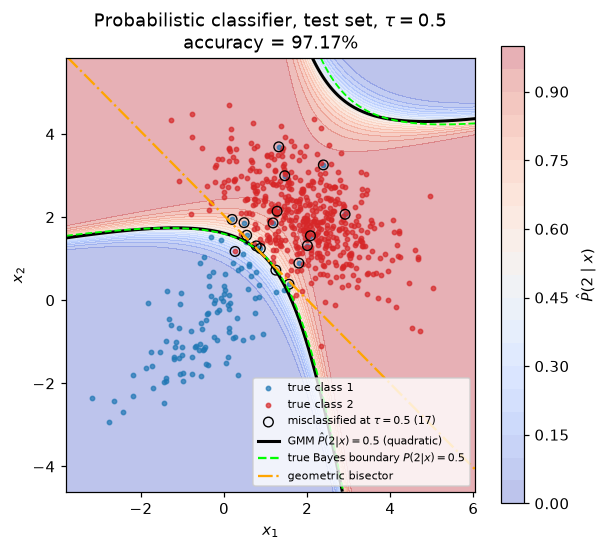

In [101]:
xx, yy = np.meshgrid(np.linspace(*lims[0], 400), np.linspace(*lims[1], 400))
grid = np.c_[xx.ravel(), yy.ravel()]
P2g = g2.predict_proba(grid)[:, c2].reshape(xx.shape)
P2t = posterior2(grid, w_true, (mu1, mu2), (Sigma1, Sigma2)).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(6, 5.4))
cf = ax.contourf(xx, yy, P2g, levels=np.linspace(0, 1, 21), cmap="coolwarm", alpha=0.35)
fig.colorbar(cf, label=r"$\hat P(2\mid x)$")
for k, col in ((1, C1), (2, C2)):
    ax.scatter(*X_test[y_test == k].T, s=8, alpha=0.7, color=col, label=f"true class {k}")
bad = yp_test != y_test
ax.scatter(*X_test[bad].T, s=40, facecolors="none", edgecolors="k", lw=0.9,
           label=f"misclassified at $\\tau=0.5$ ({bad.sum()})")
ax.contour(xx, yy, P2g, levels=[0.5], colors="k", linewidths=2)
ax.contour(xx, yy, P2t, levels=[0.5], colors="lime", linewidths=1.2, linestyles="--")
draw_bisector(ax, r_hat, m_mid, color="orange", lw=1.5, ls="-.")
ax.plot([], [], "k-", lw=2, label=r"GMM $\hat P(2|x)=0.5$ (quadratic)")
ax.plot([], [], "--", color="lime", label=r"true Bayes boundary $P(2|x)=0.5$")
ax.plot([], [], "-.", color="orange", label="geometric bisector")
ax.set(xlim=lims[0], ylim=lims[1], aspect="equal", xlabel="$x_1$", ylabel="$x_2$",
       title=fr"Probabilistic classifier, test set, $\tau=0.5$" + f"\naccuracy = {100*r_prob['acc']:.2f}%")
ax.legend(fontsize=7, loc="lower right")
fig.savefig(FIG / "prob_boundary_test.pdf")
plt.show()

***Robustness: repeat the whole pipeline for 50 independent datasets and seeds***

In [102]:
rep = []
for s in range(50):
    r_ = np.random.default_rng(1000 + s)
    Xs, ys = sample_labeled_mixture(N, r_)
    Xa, Xb, ya, yb = train_test_split(Xs, ys, test_size=0.2, random_state=1000 + s)
    g = GaussianMixture(2, covariance_type="full", n_init=5, random_state=s).fit(Xa)
    Mm = g.means_
    e0 = np.linalg.norm(Mm[0] - mu1) + np.linalg.norm(Mm[1] - mu2)
    e1 = np.linalg.norm(Mm[1] - mu1) + np.linalg.norm(Mm[0] - mu2)
    k1, k2 = (0, 1) if e0 <= e1 else (1, 0)
    rr = (Mm[k2] - Mm[k1]) / np.linalg.norm(Mm[k2] - Mm[k1]); mm = 0.5 * (Mm[k1] + Mm[k2])
    yg = np.where((Xb - mm) @ rr < 0, 1, 2)
    pp = g.predict_proba(Xb)[:, k2]
    ypr = np.where(pp >= 0.5, 2, 1)
    pt = posterior2(Xb, w_true, (mu1, mu2), (Sigma1, Sigma2))
    rep.append([np.mean(yg == yb), np.mean(ypr == yb), np.mean(np.where(pt >= .5, 2, 1) == yb),
                np.mean(yg[yb == 1] == 1), np.mean(ypr[yb == 1] == 1),
                np.mean(yg[yb == 2] == 2), np.mean(ypr[yb == 2] == 2),
                roc_auc_score(yb == 2, pp), roc_auc_score(yb == 2, (Xb - mm) @ rr)])
rep = np.array(rep)
rep_mean, rep_std = rep.mean(0), rep.std(0)

display(pd.DataFrame({"mean": rep_mean, "std": rep_std},
                     index=["acc geom", "acc prob", "acc Bayes(true)", "recall-1 geom", "recall-1 prob",
                            "recall-2 geom", "recall-2 prob", "AUC prob", "AUC geom"]).round(4))

,mean,std
acc geom,0.9521,0.0093
acc prob,0.9544,0.0093
acc Bayes(true),0.9563,0.0089
recall-1 geom,0.8150,0.0353
recall-1 prob,0.7988,0.0374
recall-2 geom,0.9860,0.0056
recall-2 prob,0.9929,0.0043
AUC prob,0.9705,0.0083
AUC geom,0.9611,0.0111


***2.7 Comparison: probabilistic vs. geometric classifier***

In [103]:
display(pd.DataFrame({"geometric bisector": r_geom, "probabilistic GMM (tau=0.5)": r_prob,
                      "Bayes, true params": r_true}).T[["acc", "recall1", "recall2", "prec1", "prec2"]].round(4))

,acc,recall1,recall2,prec1,prec2
geometric bisector,0.9617,0.8824,0.9813,0.9211,0.9712
probabilistic GMM (tau=0.5),0.9717,0.8655,0.9979,0.9904,0.9677
"Bayes, true params",0.9717,0.8739,0.9958,0.9811,0.9696


**(i) Performance.** The probabilistic classifier is better.
- On this split its test accuracy is 97.2% against 96.2%: 17 errors against 23.
- Its AUC is 0.973 against 0.961.
- It is essentially the Bayes-optimal classifier: its confusion matrix and AUC match those computed with the true parameters.

Over 50 repetitions the accuracy gap is small (95.4% against 95.2%), but the AUC advantage is consistent.

The two classifiers make different errors. The bisector ignores the priors and covariances and puts the boundary halfway between the means, so it misclassifies more class-2 points (9 against 1).
The GMM boundary is quadratic and moves toward class 1, because $\hat\pi_2\approx0.8$ and $\Sigma_2$ is tight along $\hat r$.
The geometric rule needs only the two means. The GMM also gives calibrated probabilities, so the operating point can be tuned with $\tau$.

**(ii) Easy or hard?** Moderately easy, but not separable. Accuracy is about 95–97% and AUC about 0.97.
The clouds overlap, though, so even the Bayes-optimal classifier errs on about 4–5% of points.

**(iii) Which class is harder?** Class 1. Its recall is about 80–88%, against about 99% for class 2. There are three reasons:
- *Geometry.* Along $\hat r\approx(1,1)/\sqrt2$, class 1 has variance $\hat r^\top\Sigma_1\hat r=2.05$ (sd 1.43), against $0.50$ (sd 0.71) for class 2. Both means are $\sqrt2$ from the bisector.
  That is about $1\sigma$ for class 1 (about 16% of it crosses) but $2\sigma$ for class 2 (about 2.3% crosses). Class 1's elongated covariance points straight at class 2.
- *Prior.* Class 1 is the 20% minority, so the probabilistic classifier sides with class 2 in the overlap region.
- *Data.* Fewer training points make $\hat\mu_1$ and $\hat\Sigma_1$ noisier.

In [104]:
out = dict(
    seed=SEED, n_train=int(len(X_train)), n_test=int(len(X_test)),
    n_train_class=[int((y_train == 1).sum()), int((y_train == 2).sum())],
    n_test_class=[int((y_test == 1).sum()), int((y_test == 2).sum())],
    gmm=dict(converged=bool(g2.converged_), n_iter=int(g2.n_iter_), lower_bound=float(g2.lower_bound_),
             raw_means=g2.means_.tolist(), raw_weights=g2.weights_.tolist(),
             d0=float(d0), d1=float(d1), class_to_component=class_to_component),
    fitted={k: dict(pi=float(pi_hat[k]), mu=mu_hat[k].tolist(), Sigma=Sig_hat[k].tolist()) for k in (1, 2)},
    supervised={k: dict(pi=float(sup[k][0]), mu=sup[k][1].tolist(), Sigma=sup[k][2].tolist()) for k in (1, 2)},
    z_mean={k: z_mean[k].tolist() for k in (1, 2)},
    acc_map_train=float(acc_map_train), acc_swap_train=float(acc_swap_train),
    max_post_diff=float(max_post_diff), mean_post_diff=float(mean_post_diff),
    ll_test_fit=float(ll_test_fit), ll_test_true=float(ll_test_true),
    r_hat=r_hat.tolist(), m=m_mid.tolist(), w_lin=w_lin.tolist(), w0_lin=float(w0_lin),
    lin_check=float(lin_check), lin_same_labels=lin_same_labels,
    cm_geom=cm_geom.tolist(), cm_prob=cm_prob.tolist(), cm_true=cm_true.tolist(), cm_tauJ=cm_tauJ.tolist(),
    rates_geom=r_geom, rates_prob=r_prob, rates_true=r_true, rates_tauJ=r_tauJ,
    tau_J=float(tau_J), tau_acc=float(tau_acc),
    auc_prob=float(auc_prob), auc_geom=float(auc_geom), auc_true=float(auc_true),
    best_shift=float(best_shift), best_angle=float(best_angle), acc_best_test=float(acc_best_test),
    rep_mean=rep_mean.tolist(), rep_std=rep_std.tolist(),
)
(RES / "gmm_results.json").write_text(json.dumps(out, indent=2, default=float))


def mat(A, f="{:.3f}"):
    return r"\begin{pmatrix}" + r"\\".join(" & ".join(f.format(v) for v in row) for row in A) + r"\end{pmatrix}"


def vec(v, f="{:.3f}"):
    return "(" + ", ".join(f.format(x) for x in v) + ")"

mac = {
    "Ntrain": len(X_train), "Ntest": len(X_test),
    "NtrainA": (y_train == 1).sum(), "NtrainB": (y_train == 2).sum(),
    "NtestA": (y_test == 1).sum(), "NtestB": (y_test == 2).sum(),
    "gmmIter": g2.n_iter_, "dzero": f"{d0:.4f}", "done": f"{d1:.4f}",
    "compOne": c1, "compTwo": c2,
    "rawMeanZero": vec(g2.means_[0]), "rawMeanOne": vec(g2.means_[1]),
    "piOne": f"{pi_hat[1]:.4f}", "piTwo": f"{pi_hat[2]:.4f}",
    "muOne": vec(mu_hat[1]), "muTwo": vec(mu_hat[2]),
    "SigOne": mat(Sig_hat[1]), "SigTwo": mat(Sig_hat[2]),
    "supPiOne": f"{sup[1][0]:.4f}", "supPiTwo": f"{sup[2][0]:.4f}",
    "supMuOne": vec(sup[1][1]), "supMuTwo": vec(sup[2][1]),
    "supSigOne": mat(sup[1][2]), "supSigTwo": mat(sup[2][2]),
    "zOne": vec(z_mean[1], "{:+.2f}"), "zTwo": vec(z_mean[2], "{:+.2f}"),
    "accMap": f"{100*acc_map_train:.2f}", "accSwap": f"{100*acc_swap_train:.2f}",
    "maxPostDiff": f"{max_post_diff:.4f}", "meanPostDiff": f"{mean_post_diff:.4f}",
    "llFit": f"{ll_test_fit:.4f}", "llTrue": f"{ll_test_true:.4f}",
    "rhat": vec(r_hat, "{:.4f}"), "mmid": vec(m_mid, "{:.4f}"),
    "wlin": vec(w_lin, "{:.4f}"), "wzero": f"{w0_lin:.4f}", "linCheck": f"{lin_check:.1e}",
    "aucProb": f"{auc_prob:.4f}", "aucGeom": f"{auc_geom:.4f}", "aucTrue": f"{auc_true:.4f}",
    "tauJ": f"{tau_J:.3f}", "tauAcc": f"{tau_acc:.3f}",
    "bestShift": f"{best_shift:+.2f}", "bestAngle": f"{best_angle:+.0f}", "accBestTest": f"{100*acc_best_test:.2f}",
}
for nm, cm, rr in (("Geom", cm_geom, r_geom), ("Prob", cm_prob, r_prob), ("True", cm_true, r_true),
                   ("TauJ", cm_tauJ, r_tauJ)):
    (a, b), (c, d) = cm
    mac.update({f"cm{nm}a": a, f"cm{nm}b": b, f"cm{nm}c": c, f"cm{nm}d": d,
                f"acc{nm}": f"{100*rr['acc']:.2f}", f"recOne{nm}": f"{100*rr['recall1']:.1f}",
                f"recTwo{nm}": f"{100*rr['recall2']:.1f}", f"precOne{nm}": f"{100*rr['prec1']:.1f}",
                f"precTwo{nm}": f"{100*rr['prec2']:.1f}"})
names = ["repAccGeom", "repAccProb", "repAccTrue", "repRecOneGeom", "repRecOneProb",
         "repRecTwoGeom", "repRecTwoProb", "repAucProb", "repAucGeom"]
for nm, mval, sval in zip(names, rep_mean, rep_std):
    if "Auc" in nm:
        mac[nm] = f"{mval:.4f}\\pm{sval:.4f}"
    else:
        mac[nm] = f"{100*mval:.1f}\\pm{100*sval:.1f}"
(RES / "gmm_macros.tex").write_text(
    "\n".join(f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in mac.items()) + "\n")
print("saved", RES / "gmm_results.json")

saved C:\Users\Muid\results\gmm_results.json


***Problem 3 — Particle physics: classifying the parent particle from two-body decay kinematics***

In [105]:
train = pd.read_csv("train_hw5.csv")
test = pd.read_csv("test_hw5.csv")

y = (train.label == "B").astype(int).values          # 1 = B, 0 = A
RAW = ["E1", "px1", "py1", "pz1", "E2", "px2", "py2", "pz2"]

# Physics-informed features from the two four-vectors
def physics_features(d):
    E = d.E1 + d.E2
    px, py, pz = d.px1 + d.px2, d.py1 + d.py2, d.pz1 + d.pz2
    P = np.sqrt(px**2 + py**2 + pz**2)
    f = pd.DataFrame(index=d.index)
    f["M"] = np.sqrt(np.clip(E**2 - P**2, 0, None))              # invariant mass
    p1 = np.sqrt(d.px1**2 + d.py1**2 + d.pz1**2)
    p2 = np.sqrt(d.px2**2 + d.py2**2 + d.pz2**2)
    f["cos12"] = (d.px1 * d.px2 + d.py1 * d.py2 + d.pz1 * d.pz2) / (p1 * p2)
    theta = np.arccos(np.clip(f.cos12, -1, 1))                   # opening angle
    f["theta"] = theta
    f["cot_half"] = 1.0 / np.tan(theta / 2)
    f["logE"] = np.log(E)
    f["logP"] = np.log(P)
    f["logpT"] = np.log(np.hypot(px, py))
    f["rapidity"] = 0.5 * np.log((E + pz) / (E - pz))
    f["logEmin"] = np.log(np.minimum(d.E1, d.E2))
    f["logEmax"] = np.log(np.maximum(d.E1, d.E2))
    f["zasym"] = np.abs(d.E1 - d.E2) / E                          # energy sharing
    f["gammabeta"] = P / f.M                                       # parent boost
    f["m2_d1"] = d.E1**2 - p1**2                                    # daughter masses (should be 0)
    f["m2_d2"] = d.E2**2 - p2**2
    return f


Ftr, Fte = physics_features(train), physics_features(test)
PHYS = ["M", "cos12", "cot_half", "logE", "logP", "logpT", "rapidity", "logEmin", "logEmax", "zasym"]

print("max |daughter m^2| =", float(np.abs(np.r_[Ftr.m2_d1, Ftr.m2_d2, Fte.m2_d1, Fte.m2_d2]).max()), "(massless as stated)")
print(train.label.value_counts().to_dict())
display(Ftr.assign(label=train.label).groupby("label")[["M", "theta", "logE"]].describe().round(2).T)

max |daughter m^2| = 2.7939677238464355e-09 (massless as stated)
{'B': 15986, 'A': 4014}


label              A         B
M     count  4014.00  15986.00
      mean     90.13    105.13
      std       3.66      4.48
      min      47.49      9.93
      25%      88.48    103.08
      50%      90.16    105.06
      75%      91.81    107.06
      max     115.36    230.87
theta count  4014.00  15986.00
      mean      1.93      1.94
      std       0.69      0.71
      min       0.07      0.02
      25%       1.43      1.41
      50%       2.05      2.05
      75%       2.48      2.53
      max       3.12      3.14
logE  count  4014.00  15986.00
      mean      4.91      5.06
      std       0.43      0.44
      min       4.32      4.51
      25%       4.60      4.74
      50%       4.76      4.90
      75%       5.09      5.24
      max       7.60      8.06

***Physics likelihood model with an angle-dependent mass resolution***

In [106]:
class VoigtMassModel:
    """Class-conditional mass densities with (optionally) opening-angle dependent resolution."""

    def __init__(self, angle_term=True):
        self.angle_term = angle_term

    def _unpack(self, t):
        sE = np.exp(t[0]); sT = np.exp(t[1]) if self.angle_term else 0.0
        o = 2 if self.angle_term else 1
        return sE, sT, t[o], t[o + 1], np.exp(t[o + 2]), np.exp(t[o + 3])

    def _rel_sigma(self, sE, sT, cot):
        return 0.5 * np.sqrt(2 * sE**2 + (sT * cot) ** 2)

    def class_densities(self, M, cot, t=None):
        sE, sT, mA, mB, gA, gB = self._unpack(self.theta_ if t is None else t)
        rs = self._rel_sigma(sE, sT, cot)
        return voigt_profile(M - mA, mA * rs, gA), voigt_profile(M - mB, mB * rs, gB)

    def _nll(self, t, M, cot, yy):
        pA, pB = self.class_densities(M, cot, t)
        return -np.sum(np.log(np.where(yy == 1, pB, pA) + 1e-300))

    def fit(self, M, cot, yy):
        t0 = [np.log(0.03)] + ([np.log(0.03)] if self.angle_term else []) + [90.0, 105.0, np.log(0.3), np.log(0.3)]
        r = minimize(self._nll, t0, args=(M, cot, yy), method="Nelder-Mead",
                     options=dict(maxiter=40000, maxfev=40000, xatol=1e-8, fatol=1e-8))
        r = minimize(self._nll, r.x, args=(M, cot, yy), method="BFGS")
        self.theta_, self.nll_ = r.x, r.fun
        self.piB_ = yy.mean()
        return self

    def params(self):
        sE, sT, mA, mB, gA, gB = self._unpack(self.theta_)
        return dict(sigma_E_rel=sE, sigma_theta=sT, m_A=mA, m_B=mB, Gamma_A=gA, Gamma_B=gB)

    def posterior_B(self, M, cot, piB=None):
        piB = self.piB_ if piB is None else piB
        pA, pB = self.class_densities(M, cot)
        return piB * pB / (piB * pB + (1 - piB) * pA)


Mtr, cottr = Ftr.M.values, Ftr.cot_half.values
Mte, cotte = Fte.M.values, Fte.cot_half.values

***Model comparison (5-fold stratified cross-validation on the training set)***

In [ ]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
oof = {}
sk_models = {
    "Logistic reg., raw 8 four-vector comps.": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), train[RAW].values),
    "Gradient boosting, raw 8 comps.": (HistGradientBoostingClassifier(max_iter=500, learning_rate=0.05, random_state=SEED), train[RAW].values),
    "MLP (64,64), raw 8 comps.": (make_pipeline(StandardScaler(), MLPClassifier((64, 64), alpha=1e-3, max_iter=800, early_stopping=True, random_state=SEED)), train[RAW].values),
    "Spline-logistic on $M$ only": (make_pipeline(SplineTransformer(n_knots=12, degree=3), LogisticRegression(C=10, max_iter=3000)), Ftr[["M"]].values),
    "Gradient boosting, physics features": (HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05, random_state=SEED), Ftr[PHYS].values),
    "MLP (64,64), physics features": (make_pipeline(StandardScaler(), MLPClassifier((64, 64), alpha=1e-3, max_iter=800, early_stopping=True, random_state=SEED)), Ftr[PHYS].values),
}
for name, (mdl, X) in sk_models.items():
    oof[name] = cross_val_predict(mdl, X, y, cv=cv, method="predict_proba")[:, 1]
    print("CV done:", name)

for name, ang in (("Voigt likelihood, const. resolution", False),
                  ("Voigt likelihood, $\\theta$-dependent resolution", True)):
    p = np.zeros(len(y))
    for a, b in cv.split(Mtr, y):
        m = VoigtMassModel(angle_term=ang).fit(Mtr[a], cottr[a], y[a])
        p[b] = m.posterior_B(Mtr[b], cottr[b])
    oof[name] = p
    print("CV done:", name)

BEST = "Voigt likelihood, $\\theta$-dependent resolution"
cv_table = []
for name, p in oof.items():
    pc = np.clip(p, 1e-12, 1 - 1e-12)
    cv_table.append(dict(model=name, auc=roc_auc_score(y, p), logloss=log_loss(y, pc),
                         acc=accuracy_score(y, p >= 0.5), brier=np.mean((p - y) ** 2)))
cv_df = pd.DataFrame(cv_table)
display(cv_df.round(4))

CV done: Logistic reg., raw 8 four-vector comps.
CV done: Gradient boosting, raw 8 comps.
CV done: MLP (64,64), raw 8 comps.
CV done: Spline-logistic on $M$ only
CV done: Gradient boosting, physics features
CV done: MLP (64,64), physics features
CV done: Voigt likelihood, const. resolution


In [ ]:
phys = VoigtMassModel(angle_term=True).fit(Mtr, cottr, y)
phys0 = VoigtMassModel(angle_term=False).fit(Mtr, cottr, y)
P = phys.params()
print("physics model params:", P, "NLL", phys.nll_, " const-res NLL", phys0.nll_)
LR_stat = 2 * (phys0.nll_ - phys.nll_)      # nested models, 1 extra parameter

pB_tr_oof = oof[BEST]
cm_cv = confusion_matrix(y, (pB_tr_oof >= 0.5).astype(int), labels=[0, 1])

print(f"Out-of-fold confusion matrix (rows true A,B; cols pred A,B):\n{cm_cv}")

In [ ]:
phys = VoigtMassModel(angle_term=True).fit(Mtr, cottr, y)
phys0 = VoigtMassModel(angle_term=False).fit(Mtr, cottr, y)
P = phys.params()
print("physics model params:", P, "NLL", phys.nll_, " const-res NLL", phys0.nll_)
LR_stat = 2 * (phys0.nll_ - phys.nll_)      # nested models, 1 extra parameter

pB_tr_oof = oof[BEST]
cm_cv = confusion_matrix(y, (pB_tr_oof >= 0.5).astype(int), labels=[0, 1])

print(f"Out-of-fold confusion matrix (rows true A,B; cols pred A,B):\n{cm_cv}")

***Figures: raw vs. physics features, mass spectrum, resolution, posterior, calibration and ROC***

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
for ax, c in zip(axes.ravel(), RAW):
    bins = np.linspace(*np.percentile(train[c], [0.5, 99.5]), 60)
    for lab, col in (("A", CA), ("B", CB)):
        ax.hist(train[c][train.label == lab], bins=bins, density=True, histtype="step", lw=1.4, color=col, label=lab)
    ax.set_title(c); ax.set_yticks([])
axes[0, 0].legend()
fig.suptitle("Raw four-vector components: the classes are almost indistinguishable (training set)")
fig.tight_layout()
fig.savefig(FIG / "particle_raw_features.pdf"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
bins = np.linspace(60, 140, 161)
ax = axes[0]
for lab, col in (("A", CA), ("B", CB)):
    ax.hist(Mtr[train.label == lab], bins=bins, histtype="step", lw=1.5, color=col,
            label=f"train, parent {lab} (n={np.sum(train.label == lab)})")
ax.set(xlabel=r"invariant mass $M=\sqrt{(E_1+E_2)^2-|\vec p_1+\vec p_2|^2}$", ylabel="events / 0.5",
       title="Invariant-mass spectrum (training set)", yscale="log")
ax.legend(fontsize=8)
ax = axes[1]
bins2 = np.linspace(60, 140, 81)
ax.hist(Mte, bins=bins2, color="0.4", alpha=0.6, label=f"test (n={len(Mte)})")
grid = np.linspace(60, 140, 800)
# expected test spectrum shapes using the model averaged over the test events' opening angles
dens_A = np.mean([phys.class_densities(grid, c)[0] for c in cotte], axis=0)
dens_B = np.mean([phys.class_densities(grid, c)[1] for c in cotte], axis=0)
ax.set(xlabel="invariant mass $M$", ylabel="events / 1.0", title="Test-set mass spectrum")
ax.legend(fontsize=8)
fig.savefig(FIG / "particle_mass.pdf"); plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
qb = np.quantile(cottr, np.linspace(0, 1, 13))
for lab, col, mk in (("A", CA, P["m_A"]), ("B", CB, P["m_B"])):
    sel = train.label.values == lab
    xs, ss, es = [], [], []
    for lo, hi in zip(qb[:-1], qb[1:]):
        s = sel & (cottr >= lo) & (cottr < hi)
        r = Mtr[s] / mk - 1
        q16, q84 = np.percentile(r, [16, 84])
        xs.append(np.median(cottr[s])); ss.append((q84 - q16) / 2); es.append((q84 - q16) / 2 / np.sqrt(2 * s.sum()))
    ax.errorbar(xs, ss, es, fmt="o", color=col, label=f"parent {lab}: half 68% width of $M/m_{lab}-1$")
cc = np.linspace(0.3, max(qb[-2], 8), 200)
ax.plot(cc, 0.5 * np.sqrt(2 * P["sigma_E_rel"] ** 2 + (P["sigma_theta"] * cc) ** 2), "k-",
        label=r"model $\frac{1}{2}\sqrt{2\sigma_E^2+\sigma_\theta^2\cot^2(\theta/2)}$")
ax.axhline(0.5 * np.sqrt(2) * phys0.params()["sigma_E_rel"], color="0.5", ls="--", label="constant-resolution fit")
ax.set(xscale="log", xlabel=r"$\cot(\theta/2)$  ($\theta$ = opening angle; large = boosted parent)",
       ylabel="fractional mass resolution", title="Mass resolution grows as the daughters become collinear")
ax.legend(fontsize=7)
ax = axes[1]
for lab, col, mk in (("A", CA, P["m_A"]), ("B", CB, P["m_B"])):
    sel = train.label.values == lab
    pull = (Mtr[sel] - mk) / (mk * phys._rel_sigma(P["sigma_E_rel"], P["sigma_theta"], cottr[sel]))
    ax.hist(pull, bins=np.linspace(-6, 6, 61), density=True, histtype="step", lw=1.5, color=col, label=f"parent {lab}")
zz = np.linspace(-6, 6, 300)
ax.plot(zz, norm.pdf(zz), "k--", lw=1, label="N(0,1)")
ax.set(yscale="log", xlabel=r"pull $(M-m_k)/\sigma_M(\theta)$", ylabel="density",
       title="Pulls are close to standard normal", ylim=(1e-4, 1))
ax.legend(fontsize=8)
fig.savefig(FIG / "particle_resolution.pdf"); plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(5.5, 4))
mg = np.linspace(80, 115, 600)
for cval, ls in ((0.6, "-"), (1.5, "--"), (5.0, ":"), (15.0, "-.")):
    ax.plot(mg, phys.posterior_B(mg, np.full_like(mg, cval)), ls=ls, color="k",
            label=fr"$\cot(\theta/2)={cval}$ ($\theta={np.degrees(2*np.arctan(1/cval)):.0f}^\circ$)")
ax.axvline(P["m_A"], color=CA, lw=0.8); ax.axvline(P["m_B"], color=CB, lw=0.8)
ax.set(xlabel="invariant mass $M$", ylabel=r"$P(B\mid x)$", title="Physics-model posterior (train prior)")
ax.legend(fontsize=7)
fig.savefig(FIG / "particle_posterior.pdf"); plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
for name, col in ((BEST, "k"), ("Gradient boosting, physics features", "tab:green"),
                  ("Spline-logistic on $M$ only", "tab:orange")):
    fr, mp = calibration_curve(y, oof[name], n_bins=10, strategy="uniform")
    ax.plot(mp, fr, "o-", ms=4, color=col, label=name)
ax.plot([0, 1], [0, 1], ":", color="0.5")
ax.set(xlabel=r"predicted $P(B\mid x)$ (out-of-fold)", ylabel="observed fraction of B",
       title="Reliability diagram (5-fold CV)")
ax.legend(fontsize=7)
ax = axes[1]
for name, col, ls in ((BEST, "k", "-"), ("Gradient boosting, physics features", "tab:green", "--"),
                      ("Spline-logistic on $M$ only", "tab:orange", "-."),
                      ("Gradient boosting, raw 8 comps.", "tab:purple", ":")):
    f_, t_, _ = roc_curve(y, oof[name])
    ax.plot(f_, t_, color=col, ls=ls, label=f"{name}: AUC={roc_auc_score(y, oof[name]):.4f}")
ax.set(xscale="log", xlim=(1e-3, 1), xlabel="false-positive rate (A called B)", ylabel="true-positive rate (B called B)",
       title="ROC (5-fold CV, positive = B)")
ax.legend(fontsize=7, loc="lower right")
fig.savefig(FIG / "particle_cv_roc.pdf"); plt.show()

***Bonus: counting $N_A$ and $N_B$ in the test set***

In [ ]:
def em_prior(pA_lik, pB_lik, pi0=0.5, tol=1e-12, it=10000):
    pi = pi0
    for _ in range(it):
        r = pi * pB_lik / (pi * pB_lik + (1 - pi) * pA_lik)
        new = r.mean()
        if abs(new - pi) < tol:
            break
        pi = new
    return new, r


def loglik_pi(pi, pA_lik, pB_lik):
    return np.sum(np.log(pi * pB_lik + (1 - pi) * pA_lik))


def counts_all(pBpost, pA_lik, pB_lik):
    n = len(pBpost)
    hard_B = int(np.sum(pBpost >= 0.5))
    soft_B = float(np.sum(pBpost))
    piB_em, r = em_prior(pA_lik, pB_lik, pi0=0.8)
    return dict(hard=hard_B, soft=soft_B, em=n * piB_em, em_hard=int(np.sum(r >= 0.5)))

In [ ]:
oof_lik = np.zeros((len(y), 2))
for a, b in cv.split(Mtr, y):
    m = VoigtMassModel(angle_term=True).fit(Mtr[a], cottr[a], y[a])
    oof_lik[b] = np.c_[m.class_densities(Mtr[b], cottr[b])]
piB_tr = y.mean()
oof_post = piB_tr * oof_lik[:, 1] / (piB_tr * oof_lik[:, 1] + (1 - piB_tr) * oof_lik[:, 0])

rng = np.random.default_rng(SEED)
idxA, idxB = np.flatnonzero(y == 0), np.flatnonzero(y == 1)
nT = len(test)
sim_rows = []
for fA in (0.05, 0.10, 0.20, 0.30, 0.40, 0.50):
    for rep in range(400):
        nA = rng.binomial(nT, fA)
        idx = np.r_[rng.choice(idxA, nA, replace=False), rng.choice(idxB, nT - nA, replace=False)]
        c = counts_all(oof_post[idx], oof_lik[idx, 0], oof_lik[idx, 1])
        nB = nT - nA
        sim_rows.append(dict(fA=fA, hard=2 * abs(c["hard"] - nB), soft=2 * abs(c["soft"] - nB),
                             em=2 * abs(c["em"] - nB), bias_soft=c["soft"] - nB, bias_em=c["em"] - nB,
                             bias_hard=c["hard"] - nB))
sim = pd.DataFrame(sim_rows)
sim_summary = sim.groupby("fA").agg(hard=("hard", "mean"), soft=("soft", "mean"), em=("em", "mean"),
                                    bias_hard=("bias_hard", "mean"), bias_soft=("bias_soft", "mean"),
                                    bias_em=("bias_em", "mean"), sd_em=("bias_em", "std"))
display(sim_summary.round(2))

fig, ax = plt.subplots(figsize=(5.6, 4))
for col, lab, mk in (("hard", r"hard counts ($\tau=0.5$)", "s"), ("soft", r"soft counts $\sum_j P(B|x_j)$", "o"),
                     ("em", "EM prior-adapted (ML mixing fraction)", "^")):
    ax.plot(sim_summary.index, sim_summary[col], marker=mk, label=lab)
ax.axvline(1 - piB_tr, color="0.5", ls=":", label=f"training A fraction ({1-piB_tr:.3f})")
ax.set(xlabel="true A fraction in a 500-event test set", ylabel="mean score $|\\Delta N_A|+|\\Delta N_B|$",
       title="Count-estimator study on held-out training events")
ax.legend(fontsize=7)
fig.savefig(FIG / "particle_count_sim.pdf"); plt.show()

***Final predictions on the test set***

In [ ]:
pA_te, pB_te = phys.class_densities(Mte, cotte)
post_te = phys.posterior_B(Mte, cotte)
c_te = counts_all(post_te, pA_te, pB_te)
piB_em, post_te_em = em_prior(pA_te, pB_te, pi0=0.8)

llmax = loglik_pi(piB_em, pA_te, pB_te)
f = lambda p, lev: loglik_pi(p, pA_te, pB_te) - (llmax - 0.5 * chi2.ppf(lev, 1))
ci68 = (brentq(f, 1e-6, piB_em, args=(0.6827,)), brentq(f, piB_em, 1 - 1e-6, args=(0.6827,)))
ci95 = (brentq(f, 1e-6, piB_em, args=(0.95,)), brentq(f, piB_em, 1 - 1e-6, args=(0.95,)))

bs = []
for _ in range(2000):
    i = rng.integers(0, nT, nT)
    bs.append(em_prior(pA_te[i], pB_te[i], pi0=0.8)[0])
bs = np.array(bs)

hgb = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05, random_state=SEED).fit(Ftr[PHYS].values, y)
post_hgb = hgb.predict_proba(Fte[PHYS].values)[:, 1]
# EM for a discriminative classifier (Saerens et al.): rescale posteriors by prior ratio
piB_h = piB_tr
for _ in range(1000):
    w1, w0 = piB_h / piB_tr, (1 - piB_h) / (1 - piB_tr)
    rr = w1 * post_hgb / (w1 * post_hgb + w0 * (1 - post_hgb))
    if abs(rr.mean() - piB_h) < 1e-12:
        break
    piB_h = rr.mean()
hgb_counts = dict(hard=int(np.sum(post_hgb >= 0.5)), soft=float(post_hgb.sum()), em=nT * piB_h)

N_B_pred = c_te["em"]
N_A_pred = nT - N_B_pred
(RES / "bonus_counts.txt").write_text(f"{N_A_pred:.2f} {N_B_pred:.2f}\n")
pd.DataFrame({"M": Mte, "opening_angle_deg": np.degrees(Fte.theta.values),
              "P_B_trainprior": post_te, "P_B_EMprior": post_te_em,
              "pred_label": np.where(post_te_em >= 0.5, "B", "A")}).to_csv(RES / "test_posteriors.csv", index=False)

print(f"physics model:     hard N_A = {nT - c_te['hard']},  soft N_A = {nT - c_te['soft']:.1f},  EM N_A = {nT - c_te['em']:.1f}")
print(f"gradient boosting: hard N_A = {nT - hgb_counts['hard']},  soft N_A = {nT - hgb_counts['soft']:.1f},  EM N_A = {nT - hgb_counts['em']:.1f}")
print(f"N_A 68% profile-likelihood interval: [{nT*(1-ci68[1]):.1f}, {nT*(1-ci68[0]):.1f}];  bootstrap sd = {nT*bs.std():.1f}")
print(f"\nBONUS SUBMISSION:  N_A_pred = {N_A_pred:.2f},  N_B_pred = {N_B_pred:.2f}   (sum = {N_A_pred + N_B_pred:.0f})")

In [ ]:
fig = plt.figure(figsize=(6, 4))
ax = fig.gca()
ax.hist(Mte, bins=bins2, color="0.6", label=f"test events (n={nT})")
bw = bins2[1] - bins2[0]
ax.plot(grid, nT * bw * ((1 - piB_em) * dens_A + piB_em * dens_B), "k-", lw=1.5,
        label=fr"fitted mixture, $\hat N_A={N_A_pred:.1f}$")
ax.plot(grid, nT * bw * (1 - piB_em) * dens_A, color=CA, lw=1.2, label="A component")
ax.plot(grid, nT * bw * piB_em * dens_B, color=CB, lw=1.2, label="B component")
ax.set(xlabel="invariant mass $M$", ylabel="events / 1.0", title="Test set: EM fit of the A/B mixing fraction",
       yscale="log", ylim=(0.3, None))
ax.legend(fontsize=8)
fig.savefig(FIG / "particle_test_fit.pdf"); plt.show()